# Finite Relational Clock Model v4: Accuracy, Clock Dimension, and Time Horizon

## Purpose

This notebook quantifies how well a finite, equally spaced clock spectrum can represent a system with noncommensurate energies over a finite time interval. It varies the clock energy spacing and the available clock dimension, then measures state fidelity and phase error.

**Scope:** this is a controlled numerical approximation study, not evidence that time is fundamentally circular, not a derivation of intrinsic decoherence, and not a proof of the manuscript's winding theorem.

We set \(\hbar=1\) for numerical convenience. The target Hamiltonian is diagonal with energies \(E_j\). For a candidate clock spacing \(\Delta\), approximate energies are \(\widetilde E_j=q_j\Delta\), where \(q_j=\operatorname{round}(E_j/\Delta)\). A clock of dimension \(N\) can represent these levels only when \(0\le q_j<N\). A common energy offset may be applied to all energies without changing relative phases; this notebook keeps a stated nonnegative spectrum to make the clock-range restriction explicit.

The relationally conditioned state associated with the matched spectrum is
\[
|\psi_{\Delta}(t)angle=\sum_j c_j e^{-i\widetilde E_j t}|jangle,
\]
compared with the target Schrödinger state
\[
|\psi(t)angle=\sum_j c_j e^{-iE_j t}|jangle.
\]
For normalized pure states, fidelity is \(F(t)=|\langle\psi(t)|\psi_\Delta(t)angle|^2\).

## 1. Imports and reproducible test spectrum

The selected energy levels are deliberately noncommensurate relative to a single exact spacing. Coefficients are normalized and have support on all four levels, so each energy contributes to the comparison.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

E = np.array([0.0, 0.73, 1.41, 2.26])  # dimensionless energies, hbar = 1
c = np.array([1.0, 1.0j, 0.7, 0.4*np.exp(0.6j)], dtype=complex)
c = c / np.linalg.norm(c)
assert np.isclose(np.linalg.norm(c), 1.0)
print('Target energies:', E)
print('Normalized amplitudes:', c)
print('Weights:', np.abs(c)**2)

Target energies: [0.   0.73 1.41 2.26]
Normalized amplitudes: [0.614295+0.j       0.      +0.614295j 0.430007+0.j
 0.2028  +0.138743j]
Weights: [0.377358 0.377358 0.184906 0.060377]


## 2. Approximate a spectrum for a candidate clock

The integer labels are rounded to the nearest clock-energy unit. The candidate is valid only if every label is in the clock's range. We report both the energy mismatch and its maximum phase-error bound over a time interval \([0,T]\):
\[
\max_{t\in[0,T]} |(E_j-\widetilde E_j)t|\le T\,\max_j|E_j-\widetilde E_j|.
\]
This bound can be loose because phase differences wrap around; the fidelity curve is the direct numerical metric.

In [2]:
def approximate_spectrum(E, delta, N):
    q = np.rint(E / delta).astype(int)
    valid = bool(np.all(q >= 0) and np.all(q < N))
    E_approx = q * delta
    return q, E_approx, valid

def state(t, energies, amplitudes=c):
    return amplitudes * np.exp(-1j * energies * t)

def fidelity(t, E_target, E_approx, amplitudes=c):
    psi = state(t, E_target, amplitudes)
    phi = state(t, E_approx, amplitudes)
    return np.abs(np.vdot(psi, phi))**2

def metrics(delta, N, T, samples=2001):
    q, Ea, valid = approximate_spectrum(E, delta, N)
    if not valid:
        return {'delta': delta, 'N': N, 'T': T, 'valid': False,
                'q': q, 'E_approx': Ea, 'max_energy_error': np.nan,
                'worst_fidelity': np.nan, 'mean_fidelity': np.nan,
                'phase_error_bound': np.nan}
    ts = np.linspace(0.0, T, samples)
    fs = np.array([fidelity(t, E, Ea) for t in ts])
    err = np.max(np.abs(E - Ea))
    return {'delta': delta, 'N': N, 'T': T, 'valid': True,
            'q': q, 'E_approx': Ea, 'max_energy_error': err,
            'worst_fidelity': float(fs.min()),
            'mean_fidelity': float(fs.mean()),
            'phase_error_bound': float(T * err)}

# Basic correctness checks
q, Ea, valid = approximate_spectrum(E, 0.25, 16)
assert valid and np.all(q >= 0) and np.all(q < 16)
assert np.isclose(fidelity(0.0, E, Ea), 1.0)
assert 0.0 <= fidelity(0.8, E, Ea) <= 1.0 + 1e-12
print('Example q labels:', q)
print('Example approximated energies:', Ea)
print('Example maximum energy mismatch:', np.max(np.abs(E-Ea)))

Example q labels: [0 3 6 9]
Example approximated energies: [0.   0.75 1.5  2.25]
Example maximum energy mismatch: 0.09000000000000008


## 3. Accuracy as the time horizon grows

A fixed energy mismatch generally accumulates phase error as the interval grows. The figure below shows the instantaneous fidelity for several candidate spacings. Invalid clock-range candidates are excluded.

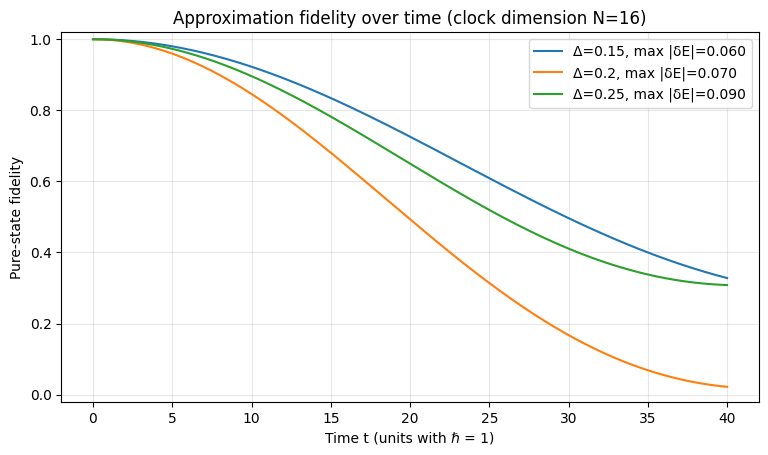

In [3]:
N_demo = 16
T_demo = 40.0
ts = np.linspace(0.0, T_demo, 1601)
deltas_demo = [0.10, 0.15, 0.20, 0.25]

plt.figure(figsize=(9, 4.8))
for delta in deltas_demo:
    q, Ea, valid = approximate_spectrum(E, delta, N_demo)
    if valid:
        fs = [fidelity(t, E, Ea) for t in ts]
        plt.plot(ts, fs, label=f'Δ={delta:g}, max |δE|={np.max(np.abs(E-Ea)):.3f}')
plt.xlabel('Time t (units with ℏ = 1)')
plt.ylabel('Pure-state fidelity')
plt.ylim(-0.02, 1.02)
plt.title(f'Approximation fidelity over time (clock dimension N={N_demo})')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 4. Clock dimension versus energy spacing

A smaller spacing improves energy resolution but requires larger integer labels to cover the same energy range. For each dimension \(N\), we scan candidate spacings and record the valid candidate with the best worst-case fidelity on the selected time horizon. This is a grid search, not a proof of global optimality.

In [4]:
def scan_candidates(N_values, delta_values, T):
    rows = []
    for N in N_values:
        for delta in delta_values:
            rows.append(metrics(float(delta), int(N), float(T)))
    return pd.DataFrame(rows)

N_values = [8, 12, 16, 24, 32, 48, 64]
delta_values = np.linspace(0.025, 0.50, 191)
T_scan = 15.0
scan = scan_candidates(N_values, delta_values, T_scan)
valid_scan = scan[scan['valid']].copy()
summary = (valid_scan.sort_values(['N', 'worst_fidelity'], ascending=[True, False])
           .groupby('N', as_index=False).first()[['N','delta','q','E_approx','max_energy_error','worst_fidelity','mean_fidelity','phase_error_bound']])
summary

,N,delta,q,E_approx,max_energy_error,worst_fidelity,mean_fidelity,phase_error_bound
0,8,0.3625,"[0, 2, 4, 6]","[0.0, 0.7250000000000001, 1.4500000000000002, ...",0.0850,0.853865,0.948618,1.2750
1,12,0.2300,"[0, 3, 6, 10]","[0.0, 0.6900000000000001, 1.3800000000000001, ...",0.0400,0.886563,0.961280,0.6000
2,16,0.1750,"[0, 4, 8, 13]","[0.0, 0.7, 1.4, 2.275]",0.0300,0.951155,0.983589,0.4500
3,24,0.1175,"[0, 6, 12, 19]","[0.0, 0.705, 1.41, 2.2325]",0.0275,0.964784,0.988201,0.4125
4,32,0.0750,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.0200,0.976770,0.992227,0.3000
5,48,0.0525,"[0, 14, 27, 43]","[0.0, 0.7350000000000001, 1.4175000000000002, ...",0.0075,0.997648,0.999216,0.1125
6,64,0.0525,"[0, 14, 27, 43]","[0.0, 0.7350000000000001, 1.4175000000000002, ...",0.0075,0.997648,0.999216,0.1125


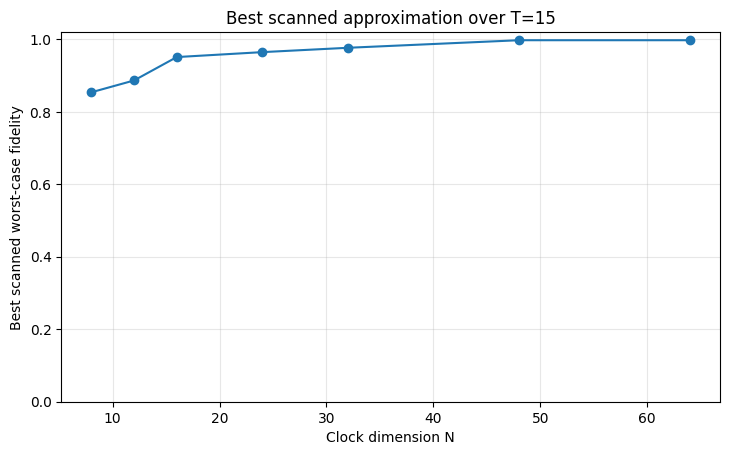

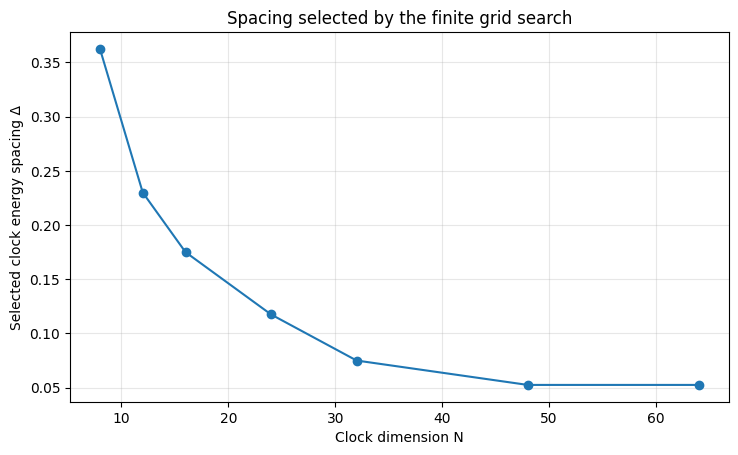

In [5]:
plt.figure(figsize=(8.5, 4.8))
plt.plot(summary['N'], summary['worst_fidelity'], marker='o')
plt.xlabel('Clock dimension N')
plt.ylabel('Best scanned worst-case fidelity')
plt.ylim(0.0, 1.02)
plt.title(f'Best scanned approximation over T={T_scan:g}')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8.5, 4.8))
plt.plot(summary['N'], summary['delta'], marker='o')
plt.xlabel('Clock dimension N')
plt.ylabel('Selected clock energy spacing Δ')
plt.title('Spacing selected by the finite grid search')
plt.grid(True, alpha=0.3)
plt.show()

## 5. Time-horizon trade-off

We repeat the scan for several time horizons. Longer horizons demand closer agreement of the relative energy gaps if high fidelity is to be maintained. Because fidelity is oscillatory, the best candidate can vary non-monotonically; the trend should be interpreted with that caveat.

In [6]:
N_horizon = 32
horizons = [2.0, 5.0, 10.0, 20.0, 40.0]
horizon_rows = []
for T in horizons:
    cand = [metrics(float(d), N_horizon, T, samples=1201) for d in delta_values]
    cand = [r for r in cand if r['valid']]
    best = max(cand, key=lambda r: r['worst_fidelity'])
    horizon_rows.append({k: best[k] for k in ['delta','N','T','q','E_approx','max_energy_error','worst_fidelity','mean_fidelity','phase_error_bound']})
horizon_summary = pd.DataFrame(horizon_rows)
horizon_summary

,delta,N,T,q,E_approx,max_energy_error,worst_fidelity,mean_fidelity,phase_error_bound
0,0.075,32,2.0,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.02,0.999583,0.999861,0.04
1,0.075,32,5.0,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.02,0.997398,0.999132,0.10
2,0.075,32,10.0,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.02,0.989625,0.996535,0.20
3,0.075,32,20.0,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.02,0.958987,0.986237,0.40
4,0.075,32,40.0,"[0, 10, 19, 30]","[0.0, 0.7500000000000001, 1.4250000000000003, ...",0.02,0.843549,0.946486,0.80


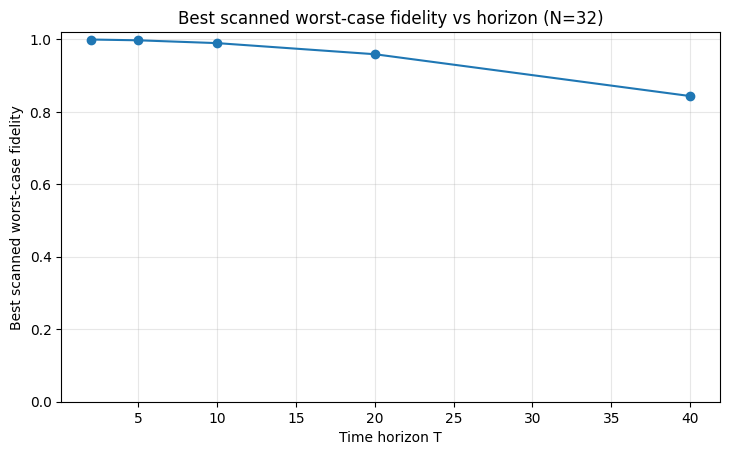

In [7]:
plt.figure(figsize=(8.5, 4.8))
plt.plot(horizon_summary['T'], horizon_summary['worst_fidelity'], marker='o')
plt.xlabel('Time horizon T')
plt.ylabel('Best scanned worst-case fidelity')
plt.ylim(0.0, 1.02)
plt.title(f'Best scanned worst-case fidelity vs horizon (N={N_horizon})')
plt.grid(True, alpha=0.3)
plt.show()

## 6. Validation checks

These checks establish internal numerical consistency, not physical validity of the underlying hypothesis.

In [8]:
# 1. Approximate energies are integer multiples of the clock spacing.
for delta in [0.1, 0.17, 0.25]:
    q, Ea, valid = approximate_spectrum(E, delta, 64)
    assert valid
    assert np.allclose(Ea / delta, q)

# 2. State norm is preserved for real energies.
for t in np.linspace(0, 10, 31):
    assert np.isclose(np.linalg.norm(state(t, E)), 1.0)

# 3. Fidelity is one at t=0 and remains in [0,1] within roundoff.
for delta in [0.1, 0.17, 0.25]:
    _, Ea, _ = approximate_spectrum(E, delta, 64)
    assert np.isclose(fidelity(0, E, Ea), 1.0)
    vals = [fidelity(t, E, Ea) for t in np.linspace(0, 20, 101)]
    assert min(vals) >= -1e-12 and max(vals) <= 1 + 1e-12

# 4. Invalid range is correctly flagged.
_, _, valid_small = approximate_spectrum(E, 0.025, 8)
assert not valid_small

# 5. Reported energy mismatch and phase-error bound are consistent.
r = metrics(0.2, 32, 12.0)
assert r['valid']
assert np.isclose(r['phase_error_bound'], r['T'] * r['max_energy_error'])

# 6. Dense scan results have valid fidelity bounds.
assert valid_scan['worst_fidelity'].between(-1e-12, 1+1e-12).all()

print('PASS: integer-spectrum consistency')
print('PASS: norm preservation')
print('PASS: fidelity bounds and t=0 limit')
print('PASS: clock-range rejection')
print('PASS: phase-error-bound arithmetic')
print('PASS: scan output validity')

PASS: integer-spectrum consistency
PASS: norm preservation
PASS: fidelity bounds and t=0 limit
PASS: clock-range rejection
PASS: phase-error-bound arithmetic
PASS: scan output validity


## 7. A rigorous fidelity bound from weighted energy mismatch

We now derive a bound that is stronger and more physically meaningful than the largest absolute energy error alone. Let \(p_j=|c_j|^2\), \(\delta_j=E_j-\widetilde E_j\), and \(\sum_jp_j=1\). The target and approximate states have overlap

\[
A(t)=\sum_j p_j e^{-i\delta_jt},\qquad F(t)=|A(t)|^2.
\]

Expanding the squared magnitude gives

\[
1-F(t)=2\sum_{j<k}p_jp_k\bigl[1-\cos((\delta_j-\delta_k)t)\bigr].
\]

Using \(1-\cos x\le x^2/2\),

\[
1-F(t)\le t^2\sum_{j<k}p_jp_k(\delta_j-\delta_k)^2
=t^2\,\operatorname{Var}_{p}(\delta),
\]

where \(\operatorname{Var}_{p}(\delta)=\sum_jp_j(\delta_j-\bar\delta)^2\) and \(\bar\delta=\sum_jp_j\delta_j\). Therefore,

\[
\boxed{F(t)\ge \max\{0,\,1-t^2\operatorname{Var}_{p}(\delta)\}.}
\]

This bound is invariant under adding the same energy offset to every mismatch: a common phase is physically unobservable in pure-state fidelity. The bound is sufficient, not generally tight, and becomes uninformative once its right-hand side reaches zero.

In [9]:
def weighted_mismatch_variance(E_target, E_approx, amplitudes=c):
    p = np.abs(amplitudes)**2
    delta_E = np.asarray(E_target) - np.asarray(E_approx)
    mean = np.sum(p * delta_E)
    return float(np.sum(p * (delta_E - mean)**2))

def fidelity_lower_bound(t, E_target, E_approx, amplitudes=c):
    var = weighted_mismatch_variance(E_target, E_approx, amplitudes)
    return max(0.0, 1.0 - float(t)**2 * var)

# Demonstrate that the bound holds at a dense set of times for a valid candidate.
delta_demo_bound, N_demo_bound, T_bound = 0.17, 32, 20.0
q_bound, Ea_bound, valid_bound = approximate_spectrum(E, delta_demo_bound, N_demo_bound)
assert valid_bound
t_bound = np.linspace(0.0, T_bound, 4001)
F_bound = np.array([fidelity(t, E, Ea_bound) for t in t_bound])
L_bound = np.array([fidelity_lower_bound(t, E, Ea_bound) for t in t_bound])
assert np.all(F_bound + 1e-11 >= L_bound)

print('Clock labels:', q_bound)
print('Target energies:', E)
print('Approximate energies:', Ea_bound)
print('Weighted mismatch variance:', weighted_mismatch_variance(E, Ea_bound))
print('Minimum numerical fidelity:', F_bound.min())
print('Minimum lower bound:', L_bound.min())
print('PASS: fidelity is above the proven lower bound on the sampled interval')

Clock labels: [ 0  4  8 13]
Target energies: [0.   0.73 1.41 2.26]
Approximate energies: [0.   0.68 1.36 2.21]
Weighted mismatch variance: 0.0005873976504093957
Minimum numerical fidelity: 0.7839797236546628
Minimum lower bound: 0.7650409398362417
PASS: fidelity is above the proven lower bound on the sampled interval


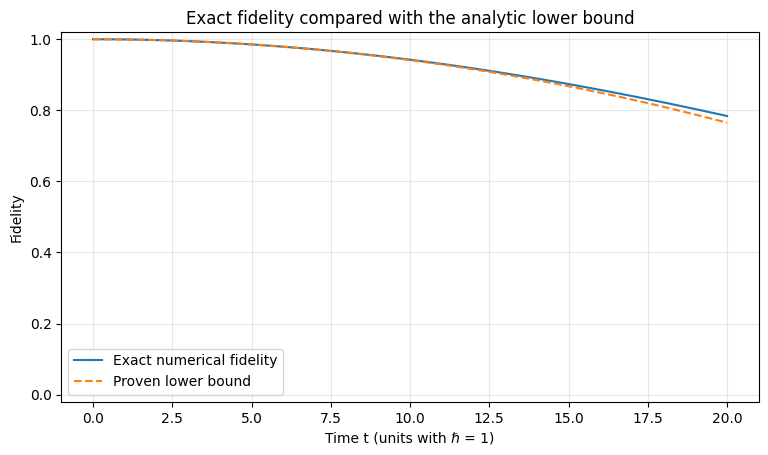

In [10]:
plt.figure(figsize=(9, 4.8))
plt.plot(t_bound, F_bound, label='Exact numerical fidelity')
plt.plot(t_bound, L_bound, '--', label='Proven lower bound')
plt.xlabel('Time t (units with ℏ = 1)')
plt.ylabel('Fidelity')
plt.ylim(-0.02, 1.02)
plt.title('Exact fidelity compared with the analytic lower bound')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Interpretation

The bound establishes a precise, coefficient-weighted sufficient condition. If the goal is \(F(t)\ge 1-\epsilon\) for every \(t\in[0,T]\), it is sufficient that

\[
T^2\operatorname{Var}_{p}(\delta)\le\epsilon.
\]

Equivalently, \(T\sqrt{\operatorname{Var}_{p}(\delta)}\le\sqrt{\epsilon}\). This is a sufficient condition, not a necessary one; oscillatory phase differences can produce high fidelity even when this bound is loose. The derivation assumes fixed, normalized amplitudes and time-independent target and approximate energy levels.

In [11]:
# Additional invariance and bound checks.
p_weights = np.abs(c)**2
mismatch = E - Ea_bound
base_var = weighted_mismatch_variance(E, Ea_bound)
# A common energy shift changes only global phase and must not change fidelity or variance.
shift = 0.413
assert np.isclose(weighted_mismatch_variance(E + shift, Ea_bound), base_var)
assert np.isclose(fidelity(3.7, E + shift, Ea_bound), fidelity(3.7, E, Ea_bound))
# The sufficient condition predicts a valid lower bound for several spectra and horizons.
for delta_test in [0.10, 0.17, 0.23, 0.31]:
    q_test, Ea_test, valid_test = approximate_spectrum(E, delta_test, 64)
    assert valid_test
    ts_test = np.linspace(0.0, 12.0, 601)
    for t in ts_test:
        assert fidelity(t, E, Ea_test) + 1e-10 >= fidelity_lower_bound(t, E, Ea_test)
print('PASS: global energy-offset invariance')
print('PASS: analytic lower bound for four candidate spectra')

PASS: global energy-offset invariance
PASS: analytic lower bound for four candidate spectra


## 7. Interpretation and next research question

### What this experiment can support

- Finite equally spaced clock spectra impose a representable energy range and a resolution trade-off.
- For a chosen set of amplitudes, energies, clock dimension, and time horizon, approximation quality can be measured using fidelity.
- A fixed energy mismatch gives the elementary phase-error bound \(T\max_j|E_j-\widetilde E_j|\), while actual fidelity may fluctuate due to interference.

### What it does not establish

- It does not prove an optimal approximation theorem; the spacing search is finite and grid-based.
- It does not show that a physical system has an intrinsic clock or that time is ontologically circular.
- It does not derive a Lindblad equation or intrinsic decoherence.
- It does not prove the proposed periodization/winding result or the manuscript's broader claims.

### A mathematically stronger next step

Replace the grid search with a stated optimization problem over relative energy-gap errors, prove an explicit sufficient fidelity bound using the coefficient weights, and compare that bound with numerics. Then test whether the bound scales predictably with clock dimension and horizon.